In [28]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

In [29]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [30]:
MAX_INTENSITY = 255.0
x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
x_test = x_test.astype("float32") / MAX_INTENSITY

N_TRAIN = 50_000
x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN:]
x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]

In [31]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]


In [32]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


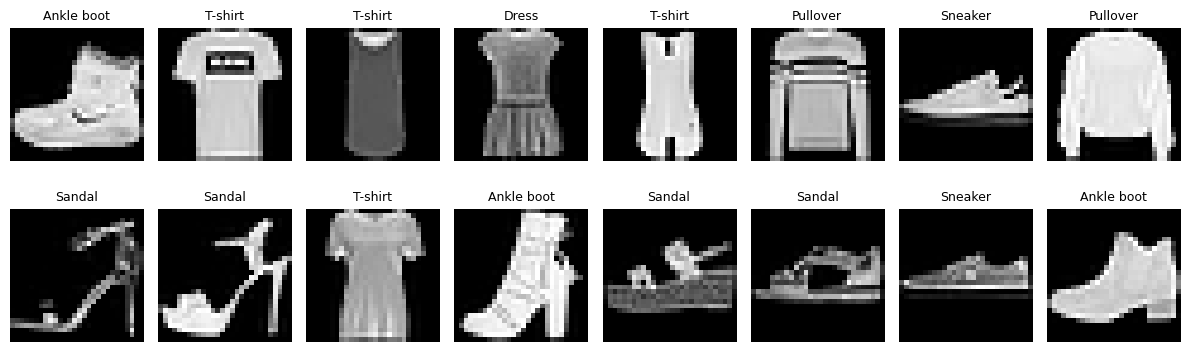

In [33]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

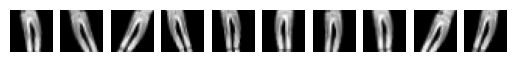

In [39]:
augmentation = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomRotation(0.1),
])

image = x_train[1500].reshape(1, 28, 28, 1)          # add a batch dimension
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(augmentation(image, training=True)[0, :, :, 0], cmap="gray")
    plt.axis("off")
plt.show()

Epoch 1/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.7230 - loss: 0.7319 - val_accuracy: 0.7887 - val_loss: 0.5582
Epoch 2/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.7973 - loss: 0.5343 - val_accuracy: 0.8243 - val_loss: 0.4593
Epoch 3/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8178 - loss: 0.4837 - val_accuracy: 0.8297 - val_loss: 0.4634
Epoch 4/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.8322 - loss: 0.4447 - val_accuracy: 0.8480 - val_loss: 0.4128
Epoch 5/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8411 - loss: 0.4261 - val_accuracy: 0.8607 - val_loss: 0.3925
Epoch 6/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8474 - loss: 0.4105 - val_accuracy: 0.8468 - val_loss: 0.4175
Epoch 7/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8529 - loss: 0.4000 - val_accuracy: 0.8661 - val_loss: 0.3684
Epoch 8/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8548 - loss: 0.3917 -

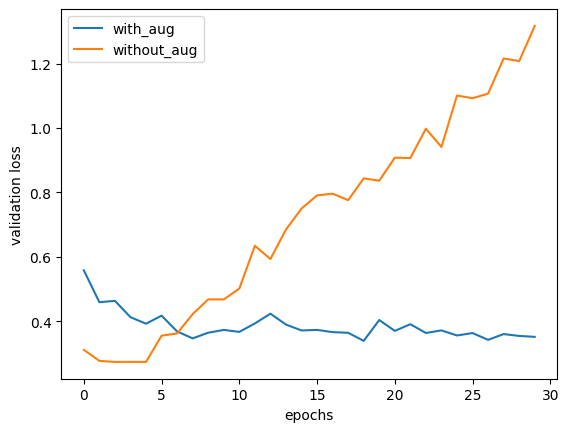

In [40]:
def make_cnn(use_augmentation):
    cnn = keras.Sequential()
    cnn.add(keras.Input(shape=(28, 28, 1)))

    if use_augmentation:
        cnn.add(augmentation)

    cnn.add(layers.Conv2D(32, 3, activation="relu"))
    cnn.add(layers.MaxPooling2D())
    cnn.add(layers.Conv2D(64, 3, activation="relu"))
    cnn.add(layers.Flatten())
    cnn.add(layers.Dense(128, activation="relu"))
    cnn.add(layers.Dense(10, activation="softmax"))
    cnn.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return cnn
x_train = x_train.reshape(-1, 28, 28, 1)
for use_aug in [True, False]:
    model = make_cnn(use_aug)
    history = model.fit(x_train, y_train, validation_split=0.2, epochs=30, batch_size=8)

    label = "with_aug" if use_aug else "without_aug"
    plt.plot(history.history["val_loss"], label=label)

plt.xlabel("epochs")
plt.ylabel("validation loss")
plt.legend()
plt.show()